# LeetCode #166: Fraction to Recurring Decimal

https://leetcode.com/problems/fraction-to-recurring-decimal/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Long Division with Hash Map ★ | O(denominator) | O(denominator) |

## Understanding the Methods
### Brute Force
No simpler approach; we need to detect cycles in the decimal expansion.

### Optimal: Long Division with Hash Map ★
Simulate long division. Track remainders in a hash map mapping remainder→position in decimal string. When a remainder repeats, we've found the cycle start; insert '(' at that position and ')' at end. Handle sign separately by XOR-ing signs. Use long arithmetic to avoid overflow.

## Solutions
### C#

In [ ]:
public class Solution {
    public string FractionToDecimal(int numerator, int denominator) {
        if (numerator == 0) return "0";
        var sb = new System.Text.StringBuilder();
        if ((numerator < 0) ^ (denominator < 0)) sb.Append('-');
        long num = Math.Abs((long)numerator);
        long den = Math.Abs((long)denominator);
        sb.Append(num / den);
        long rem = num % den;
        if (rem == 0) return sb.ToString();
        sb.Append('.');
        var map = new Dictionary<long, int>();
        while (rem != 0) {
            if (map.TryGetValue(rem, out int pos)) {
                sb.Insert(pos, '(');
                sb.Append(')');
                break;
            }
            map[rem] = sb.Length;
            rem *= 10;
            sb.Append(rem / den);
            rem %= den;
        }
        return sb.ToString();
    }
}

### Python

In [ ]:
class Solution:
    def fractionToDecimal(self, numerator: int, denominator: int) -> str:
        if numerator == 0:
            return '0'
        sign = '-' if (numerator < 0) ^ (denominator < 0) else ''
        num, den = abs(numerator), abs(denominator)
        integer_part = num // den
        rem = num % den
        if rem == 0:
            return sign + str(integer_part)
        decimal = []
        remainder_map = {}
        while rem != 0:
            if rem in remainder_map:
                idx = remainder_map[rem]
                decimal.insert(idx, '(')
                decimal.append(')')
                break
            remainder_map[rem] = len(decimal)
            rem *= 10
            decimal.append(str(rem // den))
            rem %= den
        return sign + str(integer_part) + '.' + ''.join(decimal)

### Go

In [ ]:
package main

import (
    "fmt"
    "strconv"
    "strings"
)

func fractionToDecimal(numerator int, denominator int) string {
    if numerator == 0 {
        return "0"
    }
    var sb strings.Builder
    if (numerator < 0) != (denominator < 0) {
        sb.WriteByte('-')
    }
    num := int64(numerator)
    den := int64(denominator)
    if num < 0 { num = -num }
    if den < 0 { den = -den }
    sb.WriteString(strconv.FormatInt(num/den, 10))
    rem := num % den
    if rem == 0 {
        return sb.String()
    }
    sb.WriteByte('.')
    remMap := map[int64]int{}
    result := []byte(sb.String())
    for rem != 0 {
        if pos, ok := remMap[rem]; ok {
            // insert '(' at pos
            result = append(result[:pos], append([]byte{'('}, result[pos:]...)...)
            result = append(result, ')')
            return string(result)
        }
        remMap[rem] = len(result)
        rem *= 10
        result = append(result, byte('0'+rem/den))
        rem %= den
    }
    return string(result)
}

func main() {
    fmt.Println(fractionToDecimal(1, 2))   // "0.5"
    fmt.Println(fractionToDecimal(2, 3))   // "0.(6)"
    fmt.Println(fractionToDecimal(4, 333)) // "0.(012)"
}

### Rust

In [ ]:
use std::collections::HashMap;

pub struct Solution;

impl Solution {
    pub fn fraction_to_decimal(numerator: i32, denominator: i32) -> String {
        if numerator == 0 { return "0".to_string(); }
        let mut result = String::new();
        if (numerator < 0) ^ (denominator < 0) { result.push('-'); }
        let mut num = (numerator as i64).abs();
        let den = (denominator as i64).abs();
        result.push_str(&(num / den).to_string());
        let mut rem = num % den;
        if rem == 0 { return result; }
        result.push('.');
        let mut rem_map: HashMap<i64, usize> = HashMap::new();
        let mut decimal = Vec::<char>::new();
        while rem != 0 {
            if let Some(&pos) = rem_map.get(&rem) {
                decimal.insert(pos, '(');
                decimal.push(')');
                break;
            }
            rem_map.insert(rem, decimal.len());
            rem *= 10;
            decimal.push(char::from_digit((rem / den) as u32, 10).unwrap());
            rem %= den;
        }
        result.extend(decimal);
        result
    }
}

## Examples

### 1. Common Case — Terminating Decimal
**Input:** `numerator = 1`, `denominator = 2`
Long division: $1\times10=10$, $10/2=5$ digit with remainder $0$. The remainder hits $0$, so it terminates: `"0.5"`.

### 2. Slightly Complex — Immediate Single-Digit Cycle
**Input:** `numerator = 2`, `denominator = 3`
$2\times10=20$, digit $6$, remainder $2$ — the remainder $2$ was already seen, so the cycle wraps a single digit: `"0.(6)"`.

### 3. Edge Case: Time Factor — Long Repeating Block
**Input:** `numerator = 1`, `denominator = 7`
The remainders cycle through $1,3,2,6,4,5$ before repeating, producing six repeating digits: `"0.(142857)"`.

### 4. Edge Case: Space Factor — Non-Repeating Prefix then Cycle
**Input:** `numerator = 1`, `denominator = 6`
Digit $1$ comes from remainder $1$; then remainder $4$ recurs, so only the trailing part repeats: `"0.1(6)"`. The remainder→position map locates the `(`.

### 5. Almost-Impossible but Plausible — INT_MIN, Sign, No Fraction
**Input:** `numerator = -2147483648`, `denominator = 1`
Signs differ only if exactly one is negative; here just the numerator is. $|n|/1$ divides evenly with remainder $0$, so the answer is the integer `"-2147483648"` — 64-bit arithmetic avoids overflow.


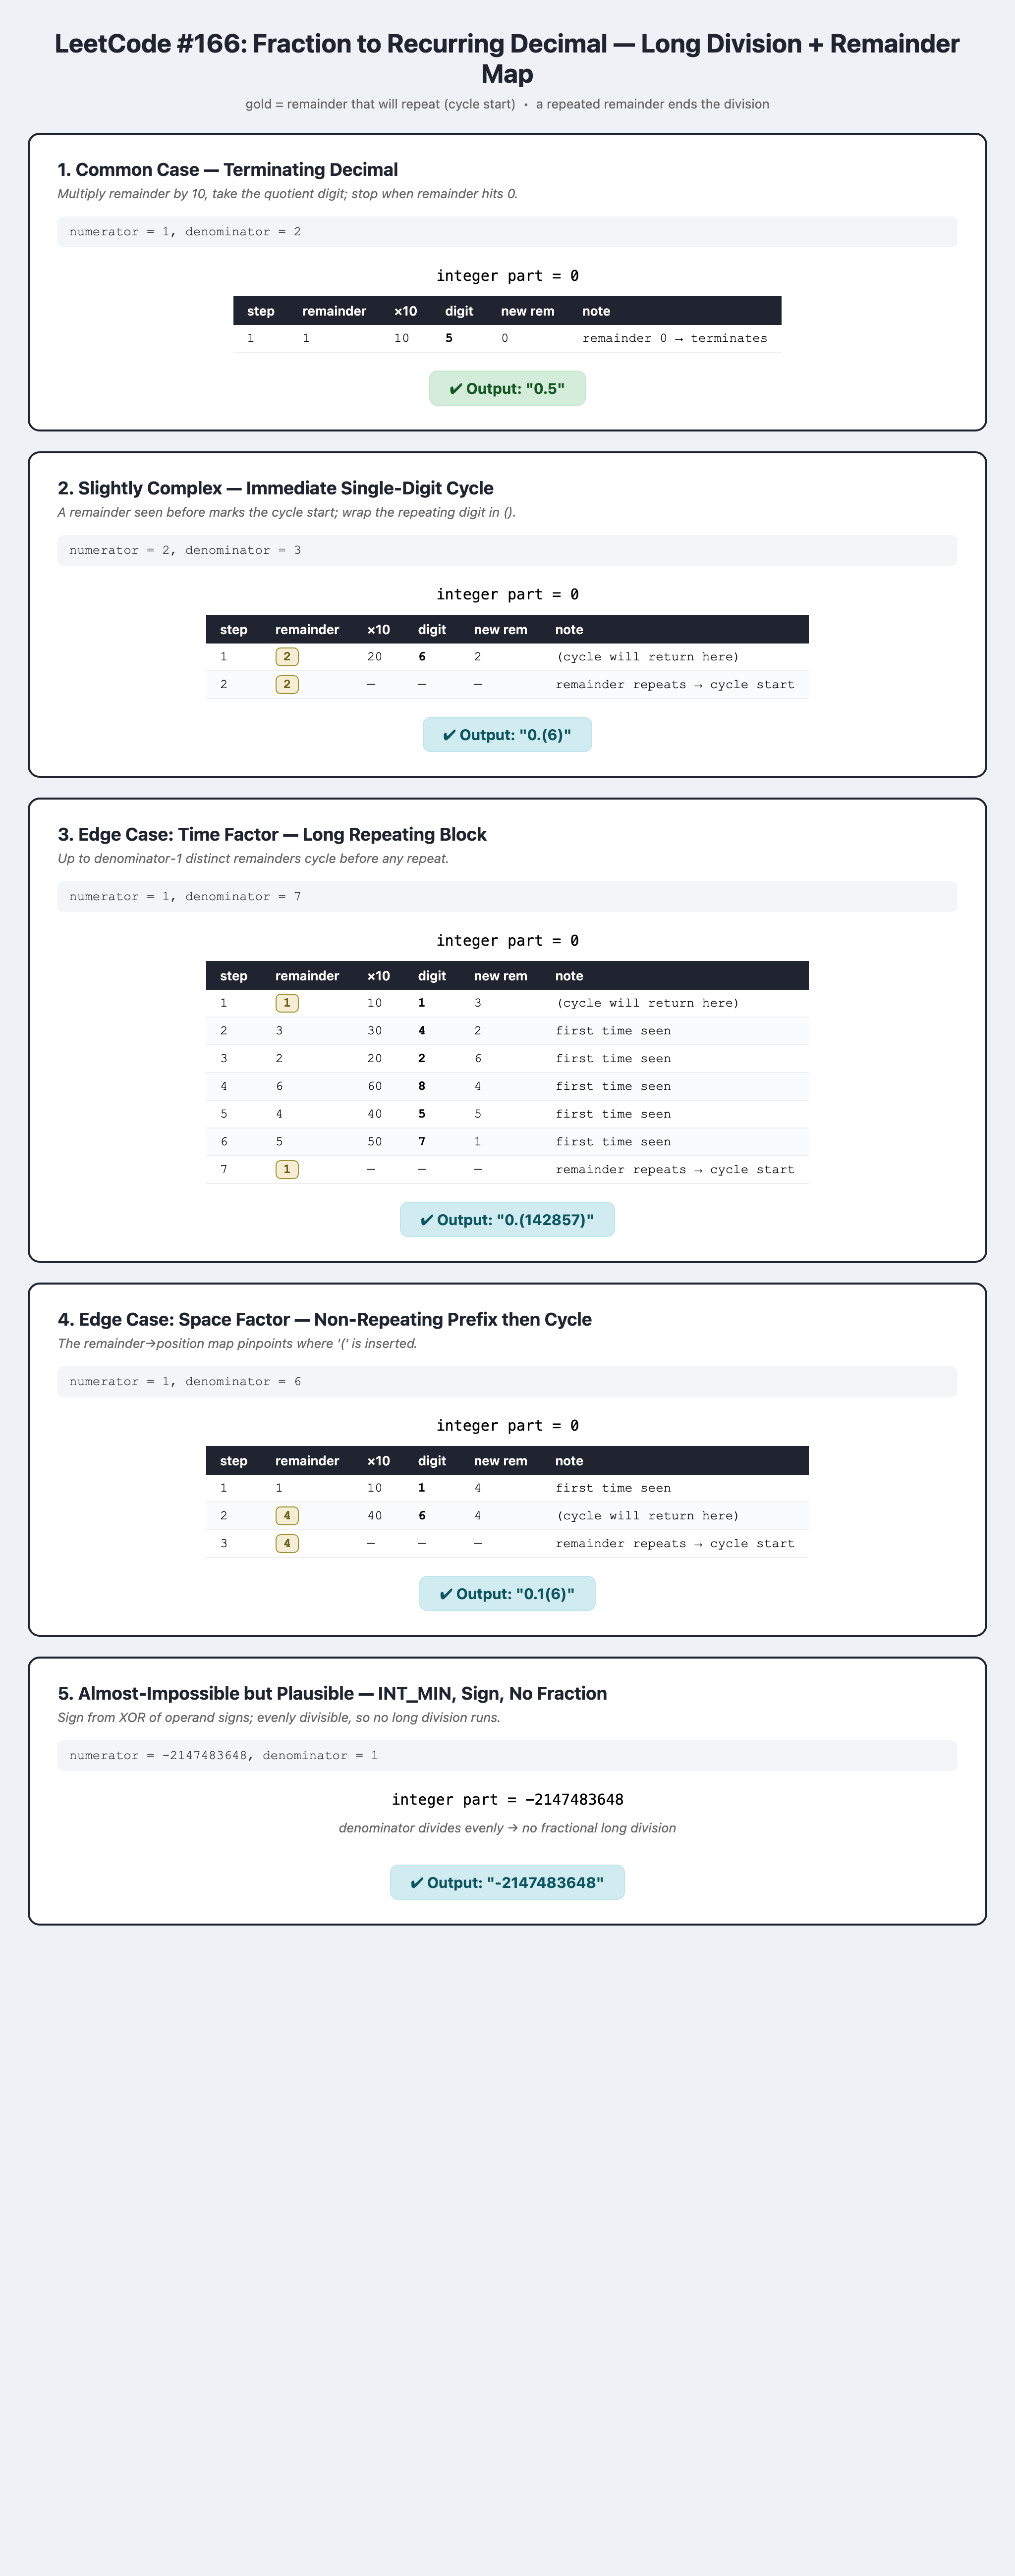